# 03 — Variant D: temporal CNN + LSTM

**Problem found in the single-month model (02):** it sees one month at a time. In summer, tall green crops scatter radar like grassland, so fields are mislabelled as grass (Heidelberg 2023: cropland 4.2 % → 1.0 % while grass 1.0 % → 6.4 % from January to June). Grass and bare ground are the weakest classes (test IoU 0.27 and 0.07).

**Idea:** a meadow looks the same all year, a wheat field goes bare → tall crop → stubble. The *sequence* separates them. An LSTM (lectures 10–11) is built to read sequences and remember earlier steps.

**Model:**
1. The trained U-Net from notebook 02 (encoder + decoder, transfer learning from our own model) turns each of 4 seasonal composites (Jan, Apr, Jul, Oct) into a 16-dim feature vector per pixel.
2. A per-pixel **LSTM** (hidden size 32) reads the 4 vectors in time order.
3. A linear layer maps the last LSTM state to the 6 classes.

**Cyclic season order:** during training the sequence is rotated at random (e.g. Apr, Jul, Oct, Jan), so the model can map *any* month from the season before it — this is how the prototype uses it.

**Fair comparison:** the test set is evaluated with all 4 rotations, i.e. 4 predictions per patch — the same number of predictions as the single-month model (one per month).

In [1]:
import sys, json, time
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from torch.utils.data import DataLoader

ROOT = Path.cwd().parent if (Path.cwd().parent / "s1lulc").exists() else Path.cwd()
sys.path.insert(0, str(ROOT))
from s1lulc import config as C
from s1lulc.data import load_stats
from s1lulc.model import CEDiceLoss, confusion, metrics
from s1lulc.temporal import TemporalDataset, build_temporal, SEQ_MONTHS

DATA = ROOT / "data"; OUT = ROOT / "models"; (ROOT / "logs").mkdir(exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CMAP = ListedColormap(C.PALETTE)
torch.manual_seed(0); np.random.seed(0)
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

device: cuda NVIDIA H200 NVL


## 1. Data: one item = 4 seasonal composites of a patch + its label

In [2]:
meta = pd.read_csv(DATA / "metadata.csv")
mean, std = load_stats(DATA / "norm_stats.json")
cw = torch.tensor(list(json.load(open(DATA / "class_weights.json")).values()), dtype=torch.float32)
BATCH = 8   # 8 sequences x 4 months = 32 images per step, same as notebook 02
ds_train = TemporalDataset(meta[meta.split == "train"], DATA / "patches", mean, std, augment=True, shift=None)
ds_val = TemporalDataset(meta[meta.split == "val"], DATA / "patches", mean, std, shift=0)
dl_train = DataLoader(ds_train, batch_size=BATCH, shuffle=True, num_workers=0, drop_last=True, pin_memory=True)
dl_val = DataLoader(ds_val, batch_size=BATCH, num_workers=0)
print("sequences: train", len(ds_train), "| val", len(ds_val), "| months", SEQ_MONTHS)

sequences: train 540 | val 108 | months [1, 4, 7, 10]


## 2. Model: U-Net features (initialised from `best_model.pt`) → per-pixel LSTM → classes

In [3]:
model = build_temporal(OUT / "best_model.pt", hidden=32, device=DEVICE)
n_all = sum(p.numel() for p in model.parameters())
n_new = sum(p.numel() for p in list(model.lstm.parameters()) + list(model.head.parameters()))
print(f"parameters: {n_all:,} total, {n_new:,} new (LSTM + head)")

parameters: 24,443,692 total, 6,598 new (LSTM + head)


## 3. Training (resumable: checkpoint after every epoch)
Two learning rates: the pretrained U-Net is fine-tuned gently (1e-4), the new LSTM and head learn faster (1e-3).

In [4]:
@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval(); cm = np.zeros((C.NUM_CLASSES,) * 2, np.int64); tot = 0.0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
            logits = model(x)
        tot += loss_fn(logits.float(), y).item() * len(x)
        cm += confusion(logits.argmax(1), y)
    return tot / len(loader.dataset), cm

def train_temporal(name="temporal_lstm", epochs=20, patience=6):
    loss_fn = CEDiceLoss(cw.to(DEVICE))
    opt = torch.optim.AdamW([{"params": model.base.parameters(), "lr": 1e-4},
                             {"params": list(model.lstm.parameters()) + list(model.head.parameters()), "lr": 1e-3}],
                            weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")
    hist, best, wait, start = [], -1.0, 0, 1
    last = OUT / f"{name}_last.pt"
    if last.exists():
        ck = torch.load(last, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
        scaler.load_state_dict(ck["scaler"]); hist, best, wait, start = ck["hist"], ck["best"], ck["wait"], ck["epoch"] + 1
        print(f"resuming from epoch {start}")
        if ck.get("done"): return pd.DataFrame(hist)
    for ep in range(start, epochs + 1):
        model.train(); t0 = time.time(); run = 0.0; cm = np.zeros((C.NUM_CLASSES,) * 2, np.int64)
        for x, y in dl_train:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
                logits = model(x)
            loss = loss_fn(logits.float(), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run += loss.item() * len(x); cm += confusion(logits.argmax(1).detach(), y)
        sched.step()
        tr = metrics(cm); vl, vcm = evaluate(model, dl_val, loss_fn); va = metrics(vcm)
        hist.append({"epoch": ep, "train_loss": run / len(ds_train), "val_loss": vl, "train_mIoU": tr["mIoU"],
                     "val_mIoU": va["mIoU"], "train_OA": tr["OA"], "val_OA": va["OA"]})
        msg = (f"{name} ep{ep:02d} loss {hist[-1]['train_loss']:.3f}/{vl:.3f}  mIoU {tr['mIoU']:.3f}/{va['mIoU']:.3f}  "
               f"OA {tr['OA']:.3f}/{va['OA']:.3f}  {time.time()-t0:.0f}s")
        print(msg); open(ROOT / "logs" / "progress_temporal.txt", "a").write(msg + "\n")
        if va["mIoU"] > best:
            best, wait = va["mIoU"], 0
            torch.save({"state_dict": model.state_dict(), "hidden": 32, "seq_months": SEQ_MONTHS, "classes": C.CLASSES,
                        "bands": C.S1_BANDS, "mean": mean.tolist(), "std": std.tolist()}, OUT / f"{name}.pt")
        else:
            wait += 1
        done = wait >= patience or ep == epochs
        pd.DataFrame(hist).to_csv(OUT / f"{name}_history.csv", index=False)
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                    "scaler": scaler.state_dict(), "hist": hist, "best": best, "wait": wait, "epoch": ep, "done": done}, last)
        if done:
            if wait >= patience: print("early stop")
            break
    return pd.DataFrame(hist)

h = train_temporal()

temporal_lstm ep01 loss 1.854/1.445  mIoU 0.316/0.457  OA 0.495/0.653  36s


temporal_lstm ep02 loss 1.122/1.176  mIoU 0.551/0.513  OA 0.736/0.715  17s


temporal_lstm ep03 loss 0.934/1.129  mIoU 0.557/0.519  OA 0.738/0.760  17s


temporal_lstm ep04 loss 0.881/1.021  mIoU 0.572/0.545  OA 0.748/0.764  17s


temporal_lstm ep05 loss 0.810/0.977  mIoU 0.593/0.560  OA 0.764/0.776  15s


temporal_lstm ep06 loss 0.779/0.974  mIoU 0.603/0.550  OA 0.774/0.748  16s


... (2 outputs left out)

temporal_lstm ep09 loss 0.744/0.964  mIoU 0.611/0.552  OA 0.782/0.760  15s


temporal_lstm ep10 loss 0.732/1.027  mIoU 0.614/0.543  OA 0.785/0.758  15s


temporal_lstm ep11 loss 0.728/0.968  mIoU 0.613/0.548  OA 0.782/0.765  14s


early stop


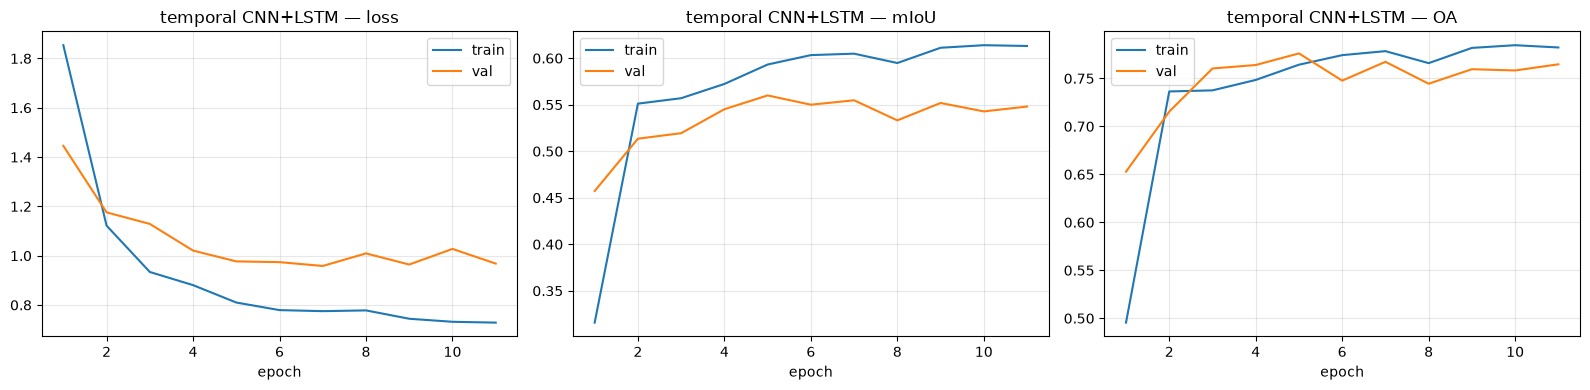

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, k in zip(ax, ["loss", "mIoU", "OA"]):
    a.plot(h.epoch, h[f"train_{k}"], label="train"); a.plot(h.epoch, h[f"val_{k}"], label="val")
    a.set_title(f"temporal CNN+LSTM — {k}"); a.set_xlabel("epoch"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / "temporal_lstm_curves.png", dpi=150); plt.show()

## 4. Test set: all 4 season rotations (4 predictions per patch, like the single-month model)

In [6]:
ck = torch.load(OUT / "temporal_lstm.pt", map_location=DEVICE, weights_only=False)
model.load_state_dict(ck["state_dict"]); model.eval()
loss_fn = CEDiceLoss(cw.to(DEVICE)); cm_t = np.zeros((C.NUM_CLASSES,) * 2, np.int64); per_end = {}
for k in range(len(SEQ_MONTHS)):
    ds_k = TemporalDataset(meta[meta.split == "test"], DATA / "patches", mean, std, shift=k)
    _, cmk = evaluate(model, DataLoader(ds_k, batch_size=BATCH), loss_fn)
    cm_t += cmk; end = (SEQ_MONTHS[k:] + SEQ_MONTHS[:k])[-1]; per_end[end] = metrics(cmk)["mIoU"]
mt = metrics(cm_t)
base = pd.read_csv(OUT / "test_results.csv").set_index("model").loc["unet_r34"]
comp = pd.DataFrame({"single-month U-Net": [base["OA"], base["mIoU"], base["mF1"]] + [base[f"IoU {c}"] for c in C.CLASSES],
                     "temporal CNN+LSTM": [mt["OA"], mt["mIoU"], mt["mF1"]] + list(mt["IoU"])},
                    index=["OA", "mIoU", "mean F1"] + [f"IoU {c}" for c in C.CLASSES])
comp["difference"] = comp.iloc[:, 1] - comp.iloc[:, 0]
comp.round(3).to_csv(OUT / "temporal_vs_single.csv")
row = {"model": "temporal_lstm", "OA": mt["OA"], "mIoU": mt["mIoU"], "mF1": mt["mF1"],
       **{f"IoU {c}": v for c, v in zip(C.CLASSES, mt["IoU"])}, **{f"F1 {c}": v for c, v in zip(C.CLASSES, mt["F1"])}}
pd.DataFrame([row]).to_csv(OUT / "test_results_temporal.csv", index=False)
print("test mIoU by last month of the sequence:", {k: round(v, 3) for k, v in per_end.items()})
comp.round(3)

test mIoU by last month of the sequence: {10: np.float64(0.542), 1: np.float64(0.537), 4: np.float64(0.539), 7: np.float64(0.544)}


,single-month U-Net,temporal CNN+LSTM,difference
OA,0.721,0.753,0.032
mIoU,0.509,0.541,0.032
mean F1,0.625,0.657,0.032
IoU Water,0.908,0.889,-0.019
IoU Built-up,0.641,0.637,-0.004
IoU Tree cover,0.522,0.574,0.052
IoU Cropland,0.651,0.731,0.080
IoU Grass/Shrub/Wetland,0.265,0.331,0.066
IoU Bare/Sparse,0.066,0.081,0.015


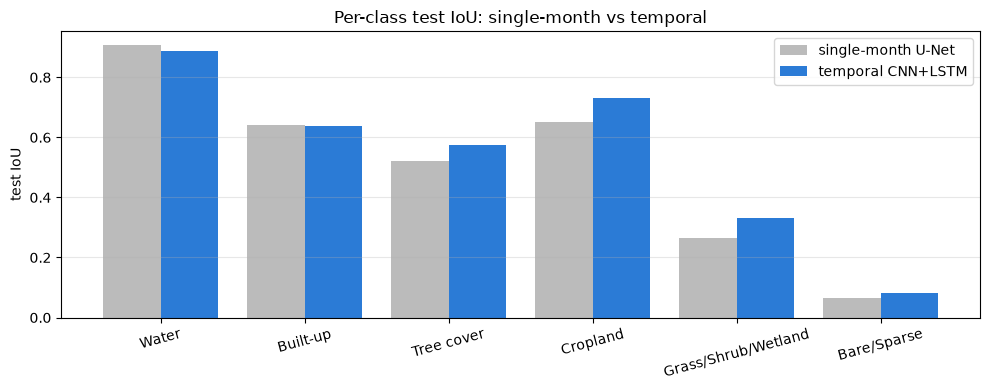

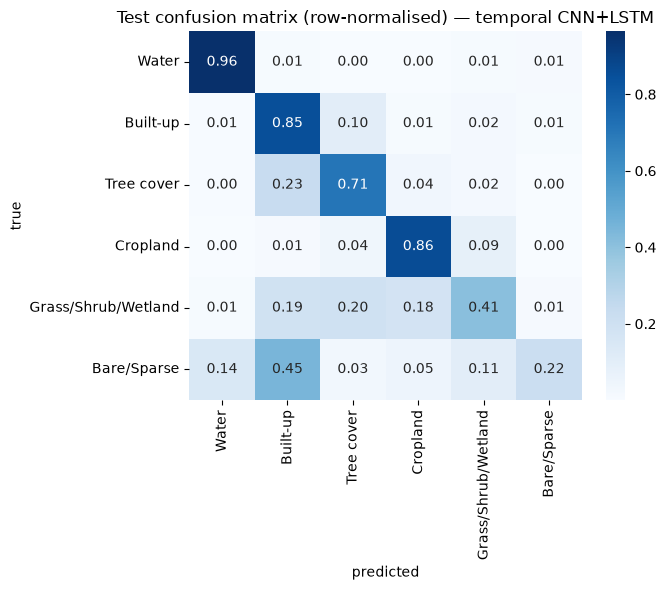

In [7]:
x = np.arange(C.NUM_CLASSES)
plt.figure(figsize=(10, 4))
plt.bar(x - 0.2, comp.iloc[3:, 0], 0.4, label="single-month U-Net", color="#bbbbbb")
plt.bar(x + 0.2, comp.iloc[3:, 1], 0.4, label="temporal CNN+LSTM", color="#2b7bd6")
plt.xticks(x, C.CLASSES, rotation=15); plt.ylabel("test IoU"); plt.legend(); plt.grid(axis="y", alpha=.3)
plt.title("Per-class test IoU: single-month vs temporal"); plt.tight_layout()
plt.savefig(OUT / "temporal_vs_single_iou.png", dpi=150); plt.show()

cmn = cm_t / cm_t.sum(1, keepdims=True)
import seaborn as sns
plt.figure(figsize=(7, 6)); sns.heatmap(cmn, annot=True, fmt=".2f", xticklabels=C.CLASSES, yticklabels=C.CLASSES, cmap="Blues")
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Test confusion matrix (row-normalised) — temporal CNN+LSTM")
plt.tight_layout(); plt.savefig(OUT / "confusion_matrix_temporal.png", dpi=150); plt.show()

## 5. Qualitative: same test patch, single-month vs temporal

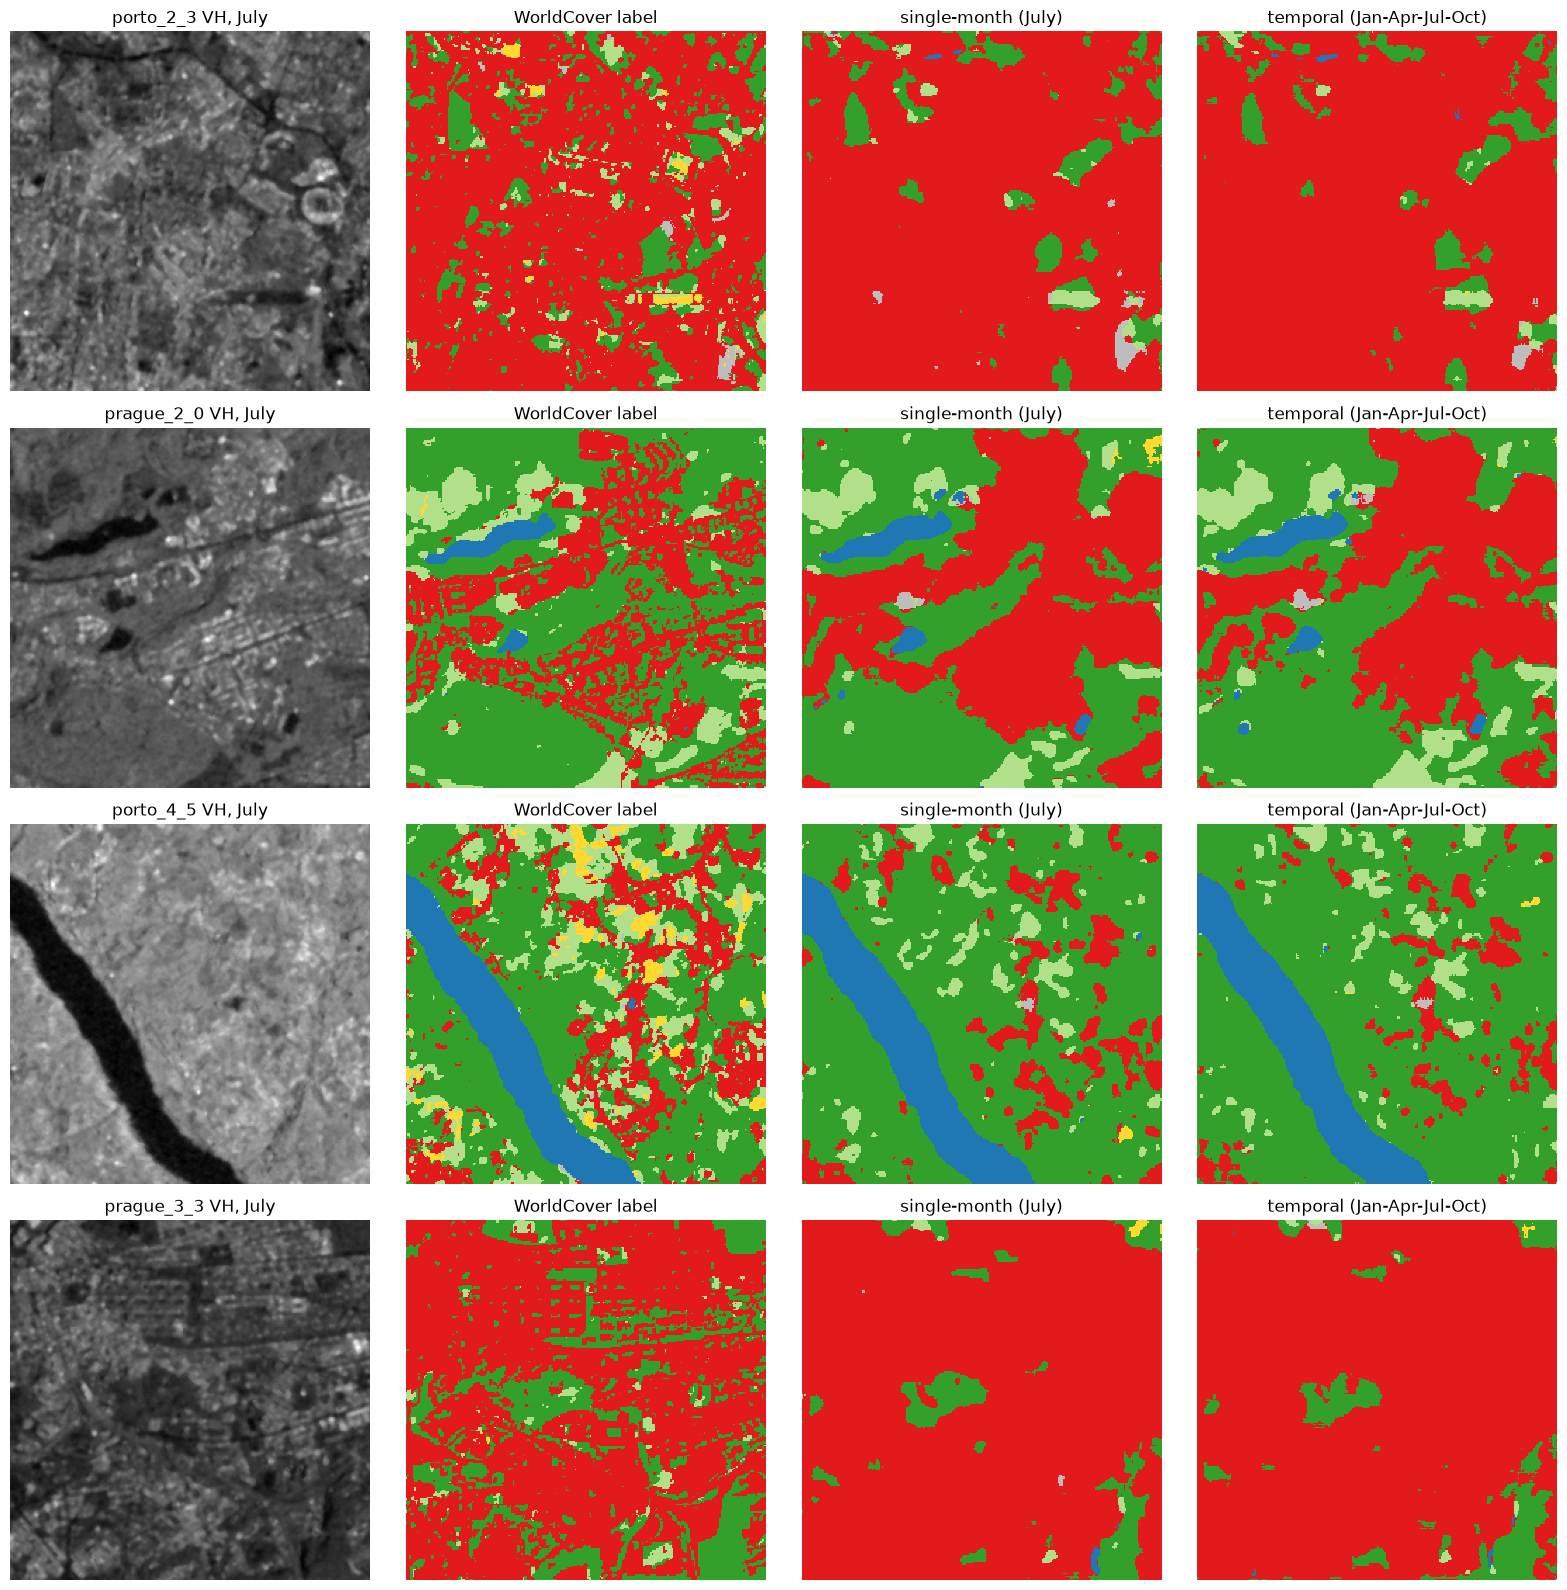

In [8]:
from s1lulc.model import build_model
single = build_model("Unet", "resnet34", pretrained=False).to(DEVICE)
single.load_state_dict(torch.load(OUT / "best_model.pt", map_location=DEVICE, weights_only=False)["state_dict"]); single.eval()
ds_test = TemporalDataset(meta[meta.split == "test"], DATA / "patches", mean, std, shift=0)
idx = np.random.RandomState(7).choice(len(ds_test), min(4, len(ds_test)), replace=False)
fig, ax = plt.subplots(len(idx), 4, figsize=(16, 4 * len(idx)), squeeze=False)
for r, i in enumerate(idx):
    x, y = ds_test[i]
    with torch.no_grad():
        pt = model(x[None].to(DEVICE)).argmax(1)[0].cpu()
        ps = single(x[2:3].to(DEVICE)).argmax(1)[0].cpu()          # July only
    yy = y.numpy().astype(float); yy[yy == C.IGNORE_INDEX] = np.nan
    ax[r, 0].imshow(x[2, 1], cmap="gray"); ax[r, 0].set_title(f"{ds_test.patches[i]} VH, July")
    ax[r, 1].imshow(yy, cmap=CMAP, vmin=0, vmax=5, interpolation="nearest"); ax[r, 1].set_title("WorldCover label")
    ax[r, 2].imshow(ps, cmap=CMAP, vmin=0, vmax=5, interpolation="nearest"); ax[r, 2].set_title("single-month (July)")
    ax[r, 3].imshow(pt, cmap=CMAP, vmin=0, vmax=5, interpolation="nearest"); ax[r, 3].set_title("temporal (Jan-Apr-Jul-Oct)")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "temporal_examples.png", dpi=110); plt.show()